In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    silhouette_score,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    adjusted_rand_score,
    normalized_mutual_info_score,
)
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans, AgglomerativeClustering
import umap

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## Крок 1. Перевірка даних та PCA

In [ ]:
# Завантаження датасету
data_raw = pd.read_csv("all_sources_isc_vgg_embeddings.csv")
print(f"Початковий розмір датасету: {data_raw.shape}")
print("\nКількість NaN у метаданих:")
print(data_raw[["source", "label", "Value"]].isna().sum())

vgg_columns = [col for col in data_raw.columns if col.startswith("vgg_")]
data_clean = data_raw.dropna(subset=vgg_columns + ["source", "label"]).reset_index(drop=True)
print(f"\nРозмір після очищення (без видалення NaN у Value): {data_clean.shape}")


# Масштабування та PCA
X_scaled = StandardScaler().fit_transform(data_clean[vgg_columns].to_numpy(dtype=np.float32))
pca = PCA(n_components=30, random_state=RANDOM_STATE)
X_embedding_pca = pca.fit_transform(X_scaled)

print(f"Пояснена дисперсія PC1: {pca.explained_variance_ratio_[0]:.2%}, PC2: {pca.explained_variance_ratio_[1]:.2%}")
print(f"Сумарна дисперсія перших 30 PC: {pca.explained_variance_ratio_.sum():.2%}")

Початковий розмір датасету: (23845, 515)

Кількість NaN у метаданих:
source        0
label         0
Value     22863
dtype: int64

Розмір після очищення (без видалення NaN у Value): (23845, 515)
Пояснена дисперсія PC1: 16.06%, PC2: 5.19%
Сумарна дисперсія перших 30 PC: 54.03%


In [31]:
data_clean['label'].value_counts()

label
I    11978
C    11591
S      276
Name: count, dtype: int64

При оцінці моделей потрібно буде врахувати дизбаланс класів та орієнтувтаись більше на balanced_accuracy, F1 score.

Розмір X_embedding_pca: (23845, 30)
Пояснена дисперсія PC1: 16.06%, PC2: 5.19%


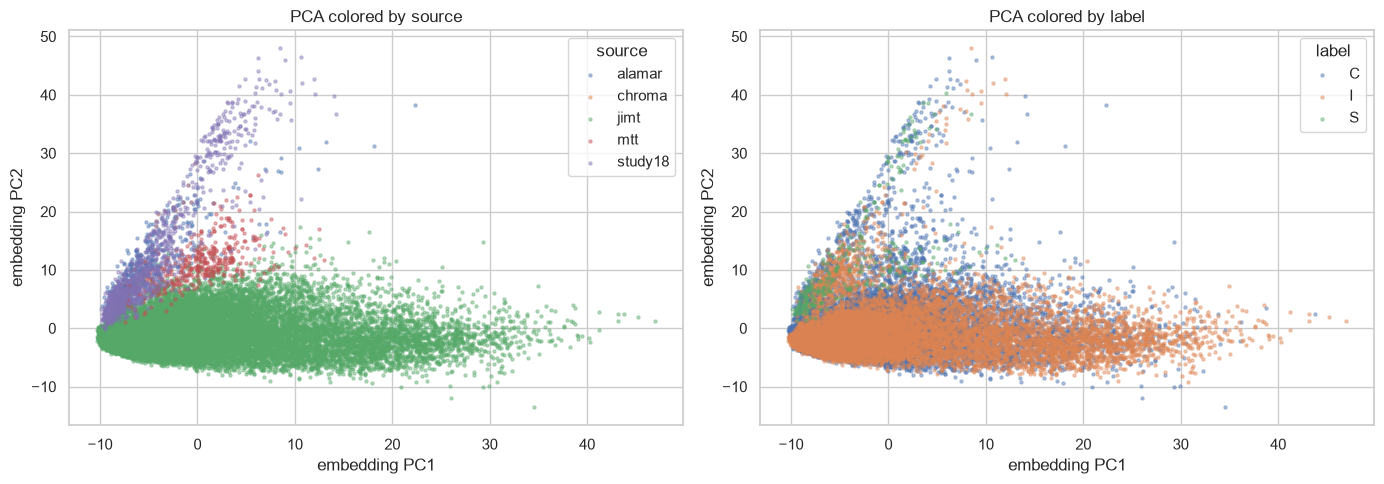

In [16]:
X_scaled_all = StandardScaler().fit_transform(data_clean[vgg_columns].to_numpy(dtype=np.float32))
pca_all = PCA(n_components=30, random_state=RANDOM_STATE)
X_embedding_pca = pca_all.fit_transform(X_scaled_all)

print(f"Розмір X_embedding_pca: {X_embedding_pca.shape}")
print(f"Пояснена дисперсія PC1: {pca_all.explained_variance_ratio_[0]:.2%}, PC2: {pca_all.explained_variance_ratio_[1]:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

source_all = data_clean["source"].to_numpy()
label_all = data_clean["label"].to_numpy()

for src in sorted(np.unique(source_all)):
    mask = source_all == src
    axes[0].scatter(X_embedding_pca[mask, 0], X_embedding_pca[mask, 1], s=5, alpha=0.4, label=src)
axes[0].set(xlabel="embedding PC1", ylabel="embedding PC2", title="PCA colored by source")
axes[0].legend(title="source")

for cls in sorted(np.unique(label_all)):
    mask = label_all == cls
    axes[1].scatter(X_embedding_pca[mask, 0], X_embedding_pca[mask, 1], s=5, alpha=0.4, label=cls)
axes[1].set(xlabel="embedding PC1", ylabel="embedding PC2", title="PCA colored by label")
axes[1].legend(title="label")

plt.tight_layout()
plt.show()

In [ ]:
Тут присутній батч ефект, так як на графіку PCA by label ми бачимо що клітини класу С кластеризуться у дві гілки що зумовлено саме технічним джерелом даних (source: нижня гілка відповідає експерименту jimt, а верхня — серіям study18, alamar та mtt), а не біологічним фенотипом.   
а живі і мертві навпаки перемішані в одному кластері що теж натякає на батч ефект.

## Крок 2. Порівняння PCA, t-SNE та UMAP і кількісна валідація

/Users/elizavetafisun/Documents/ML_Bio/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


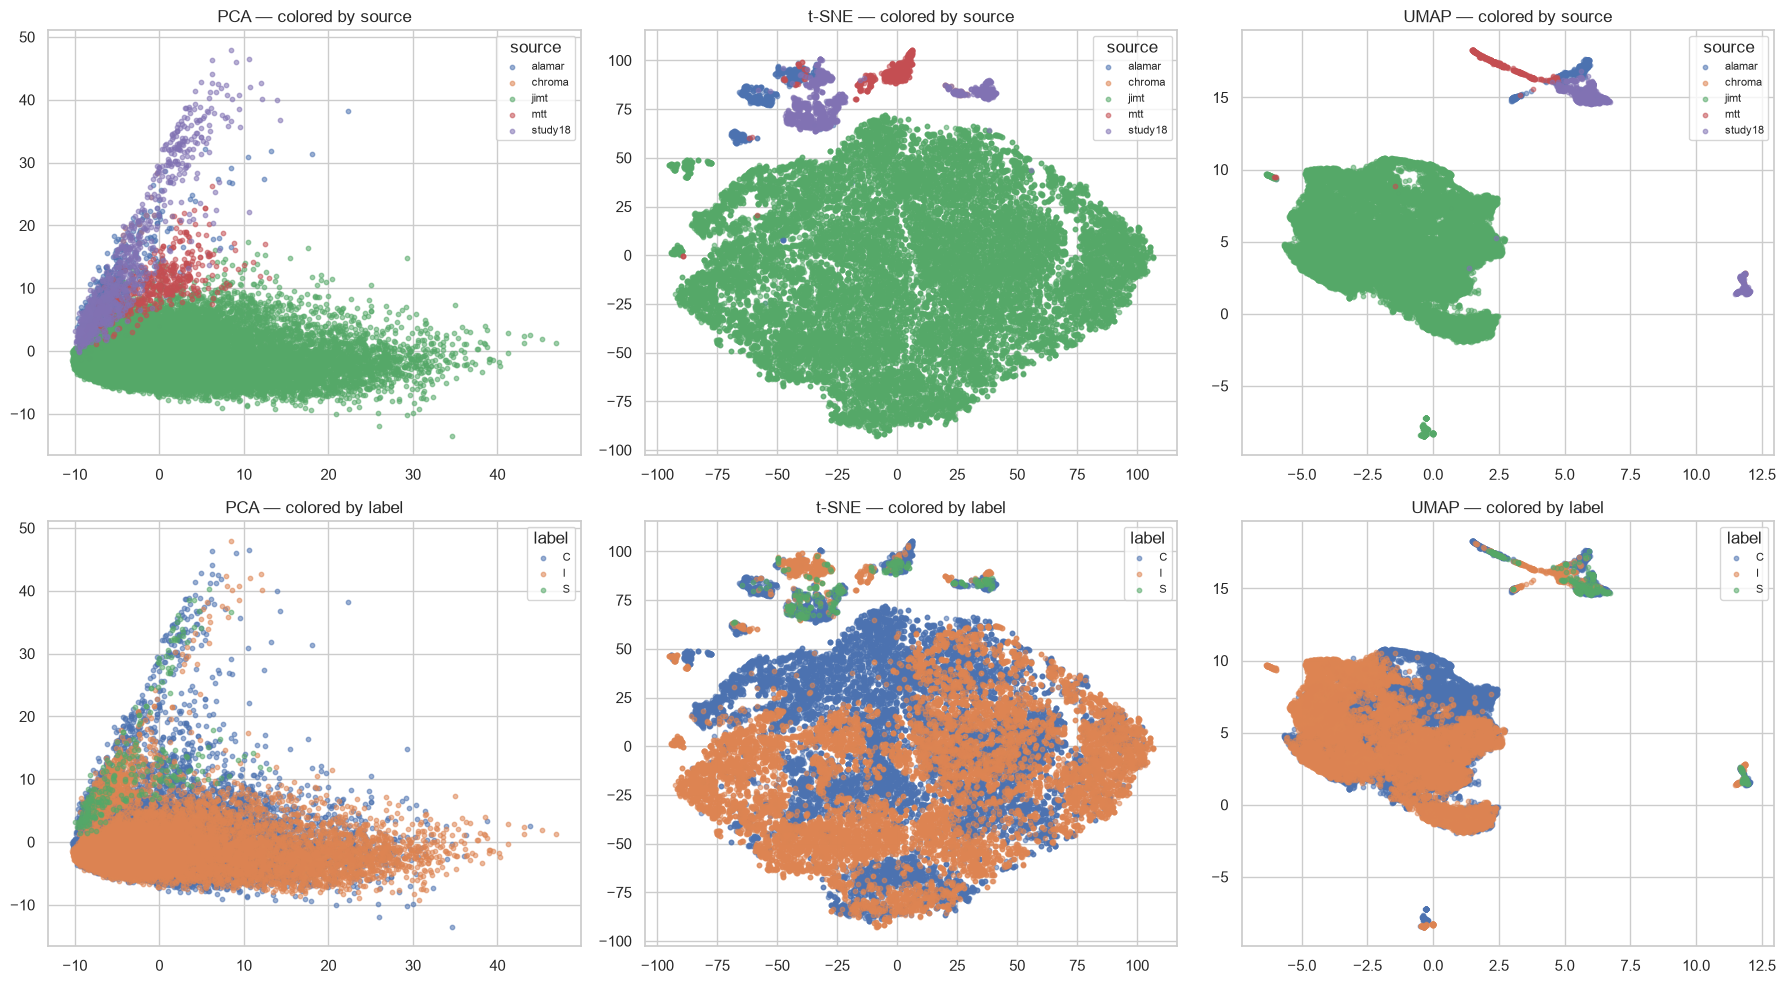

Silhouette Score (вище = краще розділення груп):
PCA   | Silhouette (source): +0.159 | Silhouette (label): -0.011
t-SNE | Silhouette (source): +0.131 | Silhouette (label): -0.060
UMAP  | Silhouette (source): +0.525 | Silhouette (label): +0.004


In [ ]:
X_tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=RANDOM_STATE,
).fit_transform(X_embedding_pca)

X_umap = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=RANDOM_STATE,
).fit_transform(X_embedding_pca)

projections = [
    ("PCA", X_embedding_pca[:, :2]),
    ("t-SNE", X_tsne),
    ("UMAP", X_umap),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for col_idx, (name, proj) in enumerate(projections):
   
    for src in sorted(np.unique(source_all)):
        mask = source_all == src
        axes[0, col_idx].scatter(proj[mask, 0], proj[mask, 1], s=10, alpha=0.55, label=src)
    axes[0, col_idx].set_title(f"{name} — colored by source")
    axes[0, col_idx].legend(title="source", fontsize=8)

    
    for cls in sorted(np.unique(label_all)):
        mask = label_all == cls
        axes[1, col_idx].scatter(proj[mask, 0], proj[mask, 1], s=10, alpha=0.55, label=cls)
    axes[1, col_idx].set_title(f"{name} — colored by label")
    axes[1, col_idx].legend(title="label", fontsize=8)

plt.tight_layout()
plt.show()


print("Silhouette Score")
for name, proj in projections:
    sil_source = silhouette_score(proj, source_all)
    sil_label = silhouette_score(proj, label_all)
    print(f"{name:5s} | Silhouette (source): {sil_source:+.3f} | Silhouette (label): {sil_label:+.3f}")

Нелінійні алгоритми зменшення розмірності t-SNE & UMAP показуються що кластеризація даних визначається джеерлом експерименту, а не біологічним класом наявність батч ефекту, що підтверджує наявність батч ефекту.  
Це також підтверджується позитивним Silhouette score.
Якщо ми детальніше подивимось на графік t-SNE by label ми бачимо що всередині кластеру сині та помаранчеві точки розділяються, що може означати що біологічний сигнал у VGG-ембедінгах точно є, але він локальний (діє всередині окремого батчу) і нелінійний, тому UMAP і t-SNE виявляють його набагато краще за лінійний PCA. 

## Крок 3. Навчання та оцінка моделей класифікації (KNN та SVM)

In [24]:
y = data_clean['label']
X_train_valid, X_test, y_train_valid, y_test = train_test_split(X_scaled_all, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

X_train, X_valid, y_train, y_valid = train_test_split(X_train_valid, y_train_valid, test_size=0.25, stratify=y_train_valid, random_state=RANDOM_STATE)


In [25]:
knn = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))])
knn.fit(X_train, y_train)
scaled_knn_metrics = classifier_metrics(knn, X_valid, y_valid)
display(pd.DataFrame([ scaled_knn_metrics], index=[ "scaled KNN"]))


,accuracy,balanced_accuracy,macro_f1
scaled KNN,0.887607,0.728557,0.738614


In [21]:
def classifier_metrics(model, X_eval, y_eval):
    predictions = model.predict(X_eval)
    return {
        "accuracy": accuracy_score(y_eval, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_eval, predictions),
        "macro_f1": f1_score(y_eval, predictions, average="macro")}

,k,accuracy,balanced_accuracy,macro_f1
0,1,0.914028,0.776120,0.760856
1,3,0.902076,0.750205,0.754191
2,5,0.887607,0.728557,0.738614
3,7,0.878381,0.704573,0.721910
4,11,0.868736,0.686218,0.704106
5,21,0.856783,0.636716,0.670326


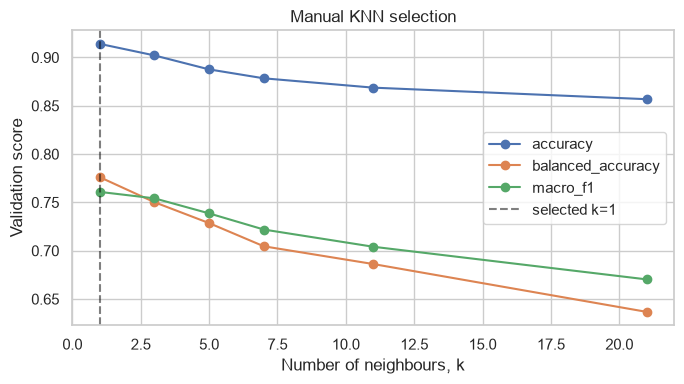

In [26]:
k_values = [1, 3, 5, 7, 11, 21]

knn_results = []
for k in k_values:
    candidate = Pipeline([
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=k))])
    candidate.fit(X_train, y_train)
    metrics = classifier_metrics(candidate, X_valid, y_valid)
    knn_results.append({"k": k, **metrics})

knn_results = pd.DataFrame(knn_results)
display(knn_results)
best_k = int(knn_results.loc[knn_results["macro_f1"].idxmax(), "k"])

plt.figure(figsize=(7, 4))
for metric in ["accuracy", "balanced_accuracy", "macro_f1"]:
    plt.plot(knn_results["k"], knn_results[metric], marker="o", label=metric)
plt.axvline(best_k, color="black", linestyle="--", alpha=0.5, label=f"selected k={best_k}")
plt.xlabel("Number of neighbours, k")
plt.ylabel("Validation score")
plt.title("Manual KNN selection")
plt.legend()
plt.tight_layout()
plt.show()


Підбір гіперпараметра k для KNN: За результатами валідації найкращі значення метрик (accuracy ≈ 0.91, balanced_accuracy ≈ 0.78, macro_f1 ≈ 0.76) досягаються при k = 1. Зі збільшенням k метрики погіршуються.

In [27]:
svm_linear = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(kernel="linear", C=0.01)),
])
svm_linear.fit(X_train, y_train)
linear_svm_metrics = classifier_metrics(svm_linear, X_valid, y_valid)
display(pd.Series(linear_svm_metrics, name="linear SVM").to_frame())


,linear SVM
accuracy,0.850493
balanced_accuracy,0.680139
macro_f1,0.700369


In [28]:
svm_rbf = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(kernel="rbf", C=1, gamma=0.01)),
])
svm_rbf.fit(X_train, y_train)
rbf_svm_metrics = classifier_metrics(svm_rbf, X_valid, y_valid)
display(pd.Series(rbf_svm_metrics, name="RBF SVM").to_frame())


,RBF SVM
accuracy,0.884043
balanced_accuracy,0.613459
macro_f1,0.626173


In [29]:
poly_rbf = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(kernel="poly", C=10, degree=3)),
])
poly_rbf.fit(X_train, y_train)
poly_svm_metrics = classifier_metrics(poly_rbf, X_valid, y_valid)
display(pd.Series(poly_svm_metrics, name="Poly SVM").to_frame())

,Poly SVM
accuracy,0.897043
balanced_accuracy,0.747100
macro_f1,0.759431


Poly SVM показує найкращі скори, тобто він краще дозволяє розділити класи комбінуючи ознаки як source x label.

## Крок 4. Unsupervised clustering (K-Means та Agglomerative Clustering)

In [34]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
clusters_km = kmeans.fit_predict(X_embedding_pca)

agg = AgglomerativeClustering(n_clusters=3, linkage="ward")
clusters_agg = agg.fit_predict(X_embedding_pca)

for name, cl_labels in [("K-Means (k=3)", clusters_km), ("Agglomerative (Ward, k=3)", clusters_agg)]:
    ari_lbl = adjusted_rand_score(label_all, cl_labels)
    nmi_lbl = normalized_mutual_info_score(label_all, cl_labels)
    ari_src = adjusted_rand_score(source_all, cl_labels)

    print(f"=== {name} ===")
    print(f"ARI vs label: {ari_lbl:.4f} | NMI vs label: {nmi_lbl:.4f} | ARI vs source: {ari_src:.4f}")
    print("Таблиця спряженості (Cluster vs Label):")
    print(pd.crosstab(pd.Series(cl_labels, name="Cluster"), pd.Series(label_all, name="Label")))
    print("\nТаблиця спряженості (Cluster vs Source):")
    print(pd.crosstab(pd.Series(cl_labels, name="Cluster"), pd.Series(source_all, name="Source")), "\n")

=== K-Means (k=3) ===
ARI vs label: 0.0151 | NMI vs label: 0.0263 | ARI vs source: 0.2174
Таблиця спряженості (Cluster vs Label):
Label       C     I    S
Cluster                 
0        8624  8458   99
1        2263  3075    0
2         704   445  177

Таблиця спряженості (Cluster vs Source):
Source   alamar  chroma   jimt  mtt  study18
Cluster                                     
0           188       0  16510   43      440
1             0       0   5338    0        0
2           365      13      0  386      562 

=== Agglomerative (Ward, k=3) ===
ARI vs label: 0.0230 | NMI vs label: 0.0423 | ARI vs source: 0.2770
Таблиця спряженості (Cluster vs Label):
Label       C     I    S
Cluster                 
0        3240  3239    0
1        1051   555  273
2        7300  8184    3

Таблиця спряженості (Cluster vs Source):
Source   alamar  chroma   jimt  mtt  study18
Cluster                                     
0             1       0   6478    0        0
1           442      13      0  

ARI досить низький що говорить про рандом, NMI також тобто unsupervised підходи не змогли розділити біологічні класи.  
Також ми бачимо що у підкластері jimt (0 та 1) живі та мертві клітини перемішані.
у сирих VGG-ембедінгах глобальна дисперсія визначається технічними відмінностями між експериментами (батч-ефектом), тому методи без учителя групують зображення за source (0.2174 для K-Means та 0.2770 для Agglomerative Clustering). Водночас біологічний сигнал життєздатності присутній локально всередині кожного батчу, завдяки чому методи з учителем (Poly SVM та KNN) успішно навчаються розрізняти класи C, I та S із високою точністю.

## Крок 5. Аналіз значень `Value` та джерел для розшифровки міток `C`, `I`, `S`

Статистика колонки Value за мітками (C, I, S):
       count        mean        std     min         25%         50%  \
label                                                                 
C      542.0  133.057841  43.289625  90.220  101.555000  117.488889   
I      366.0   23.301403  17.626274   2.454   10.050000   14.750000   
S       74.0   79.910811   5.119226  70.030   74.848889   78.890000   

              75%         max  
label                          
C      151.700000  271.664444  
I       32.045000   69.730000  
S       83.427778   89.970000  

Розподіл міток по джерелах (source):
label        C      I    S
source                    
alamar     307    230   16
chroma       4      5    4
jimt     10464  11384    0
mtt        235    136   58
study18    581    223  198


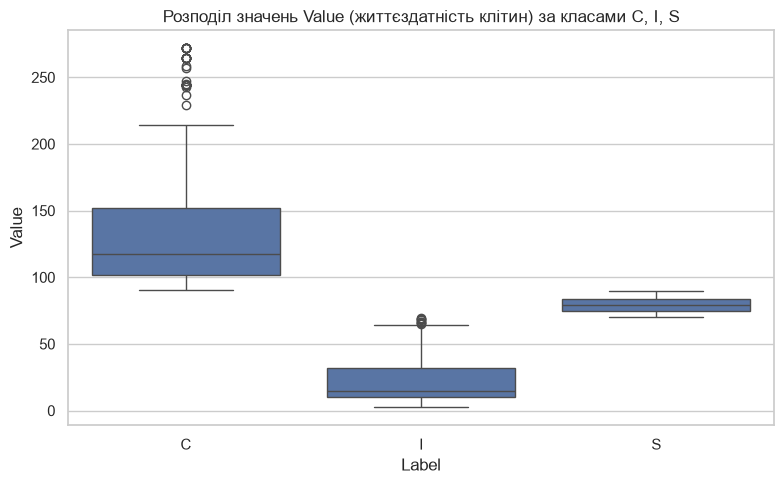

In [7]:
print("Статистика колонки Value за мітками (C, I, S):")
print(data_raw.groupby("label")["Value"].describe())

print("\nРозподіл міток по джерелах (source):")
print(pd.crosstab(data_raw["source"], data_raw["label"]))

plt.figure(figsize=(8, 5))
sns.boxplot(data=data_raw.dropna(subset=["Value", "label"]), x="label", y="Value", order=["C", "I", "S"])
plt.title("Розподіл значень Value (життєздатність клітин) за класами C, I, S")
plt.xlabel("Label")
plt.ylabel("Value")
plt.tight_layout()
plt.show()

* Базуючись на цьому розподілі клітини класу C це ймовірно живі клітини, так як їх value переважно більше 90%, діапазон від 90.22 до 271.66, медіана 117.49.  
* I - загибель клітин, Value < 70% (діапазон від 2.45 до 69.73, медіана 14.75). 
* S - проміжний стан, але життєдіяльність пригнічено і також таких семплів менше всього, деякі експерименти взагалі їх не мали.